# Problem set 5: Printing and plotting - comments/solutions

# Programming for Economists Autumn 2026: Class 3
**Matias BF Hall**

We use the CES consumer from the lectures to practise printing, files and plotting: a utility table, indifference curves, an income distribution and a budget set. The same CES function returns in Problem set 6. Below each task, a cell imports the answer (`A1.py`, `A2.py`, ...) and shows the target output.

**Learning goals**:

- Print results with f-strings: widths, decimals and thousands separators
- Build a text table with a nested loop and a function passed as an argument
- Write, append and read text files with `'w'`, `'a'` and `'r'`
- Plot lines, histograms and scatter plots with labels, legends, colors and line styles, and save them with `fig.savefig`
- Select data with Boolean masks and build a grid with `np.meshgrid`
- Optional: draw a 3D surface with `plot_surface`

**Table of contents**<a id='toc0_'></a>    
- 1. [CES utility](#toc1_)    
- 2. [A readable utility table](#toc2_)    
- 3. [Save, append and read back](#toc3_)    
- 4. [Indifference curves](#toc4_)    
- 5. [Income distribution](#toc5_)    
- 6. [The budget set](#toc6_)    
- 7. [Optional: utility in 3D](#toc7_)    

<!-- vscode-jupyter-toc-config
	numbering=true
	anchor=true
	flat=false
	minLevel=2
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

Imports you will need:

In [14]:
# Here we import packages we will use in the notebook
# We import numpy for numerical operations and matplotlib for plotting
# We import as shortened names to make it easier to call functions from these packages e.g. np.array instead of numpy.array
import numpy as np
import matplotlib.pyplot as plt

# predefine options for all plots
plt.rcParams.update({'axes.grid':True,'grid.color':'black','grid.alpha':'0.25','grid.linestyle':'-'})
plt.rcParams.update({'font.size': 14})

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

## 1. <a id='toc1_'></a>[CES utility](#toc0_)

Implement the CES utility function as `u_func(x1,x2,alpha=0.5,beta=1.0)`:

$$
u(x_1,x_2) = (\alpha x_1^{-\beta} + (1-\alpha) x_2^{-\beta})^{-1/\beta}, \qquad \beta > 0
$$

`x1` and `x2` are positional arguments, `alpha` and `beta` are keyword arguments with the defaults shown. Both quantities must be strictly positive: with $\beta>0$, a zero quantity means a negative power of zero. Write the formula so that `x1` and `x2` can also be NumPy arrays, which you need from Task 4 on.

Then print one evaluation with an f-string and three decimals, in the form `u(2.0, 4.0) = 2.667`.

In [15]:
# these values are used
x1 = 2.0
x2 = 4.0

In [19]:
# under 'def' we define the name of the function and the arguments it takes
# after 'return' we tell what calling the function will return
def utility(x1,x2,alpha=0.5,beta=1):
    return (alpha*x1**(-beta) + (1-alpha)*x2**(-beta))**(-1/beta)

# x1 and x2 are positional arguments and must be called in the correct order
# alpha and beta are keyword arguments and can be called in any order, and have default values
# e.g. utility(1,2,beta=2) or utility(1,2,alpha=0.3) or utility(1,2,alpha=0.3,beta=2)

# print using the values above to test it
print(f'utility(x1,x2) = {utility(x1,x2):.3f}')

utility(x1,x2) = 2.667


## 2. <a id='toc2_'></a>[A readable utility table](#toc0_)

Write a function `gen_table(x1_vec,x2_vec,u_func)` that **returns** a text table of $u(x_1,x_2)$. The header row shows the $x_2$ values, and each row starts with its $x_1$ value. Use width 8 for every column, one decimal for $x_1$ and $x_2$, and three decimals for $u$.

Two things are new compared with the lecture:

1. a loop inside a loop: one row per $x_1$, and inside it one column per $x_2$;
2. the utility function arrives as an argument. A function is an object and can be passed to another function (see *A function is an object* in the functions notebook), so `gen_table` works with any utility function.

The header is given below. The call passes your `u_func` from Task 1. (`f'{"":8s}'` is an empty string padded to width 8.)

**Question:** In the row $x_1 = 0.5$ the values rise with $x_2$ but seem to stop below 1. Why, and which bound holds for a general $x_1$?

In [20]:
# these values are used
x1_vec = [0.5, 1, 2, 4]
x2_vec = [1, 2, 3, 4, 5]

In [23]:
# complete the function (the header is given)

def gen_table(x1_vec, x2_vec, u_func):

    # a. empty text
    text = ''

    # b. top header: empty corner, then the x2 values
    text += f'{"":8s}' # formats the empty string to be 8 characters wide, and a string(s) and adds it to text
    for x2 in x2_vec: # loop over the x2 values
        text += f'{x2:8.1f}' # formats x2 to be 8 characters wide with 1 decimal place and adds it to text
    text += '\n' # line shift

    # c. body: one row per x1 value
    for i, x1 in enumerate(x1_vec):
        if i > 0: text+='\n'
        # adds a line shift for each iteration except the first as we already did above
        text += f'{x1:8.1F}' # the row header # formats the x2 value to be 8 characters wide, and a float(f) and adds it to text
        for j, x2 in enumerate(x2_vec): # loop over the x2 values
            text += f'{u_func(x1,x2):8.3f}'
            # formats the utility value to be 8 characters wide, with 3 decimals and adds it to text
    return text # returns the text string to the caller

table = gen_table(x1_vec, x2_vec, utility)
print(table)

             1.0     2.0     3.0     4.0     5.0
     0.5   0.667   0.800   0.857   0.889   0.909
     1.0   1.000   1.333   1.500   1.600   1.667
     2.0   1.333   2.000   2.400   2.667   2.857
     4.0   1.600   2.667   3.429   4.000   4.444


### Extra
Do you see a slightly more elegant solution with the newline above. HINT(You can remove the "if i>0" statement by removing other code). See solution below. If you want one more challenge you can think about how we can create both the header and body in the same loop using if statements - this last solution will not be elegant, but is more of a logical puzzle for the ones who want to give it a go.

In [26]:
def gen_table_extra(x1_vec,x2_vec,u_func):
    # a. empty text
    text = ''
    # b. top header
    text += f'{"":8s}'
    for x2 in x2_vec:
       text += f'{x2:8.1f}' 
    # c. body
    for x1 in x1_vec: # no  need to use enumerate for the x1 loop
        text+='\n'
        # adding the line shift here instead of outside the loop lets us remove the if statement
        text += f'{x1:8.1f}'
        for x2 in x2_vec: # no need to use enumerate for the x2 loop
            text += f'{u_func(x1,x2):8.3f}'
    # d. print
    return text

table_extra = gen_table_extra(x1_vec,x2_vec,utility)
print(table_extra)

             1.0     2.0     3.0     4.0     5.0
     0.5   0.667   0.800   0.857   0.889   0.909
     1.0   1.000   1.333   1.500   1.600   1.667
     2.0   1.333   2.000   2.400   2.667   2.857
     4.0   1.600   2.667   3.429   4.000   4.444


<details>
<summary><strong>Answer</strong></summary>

For $\alpha=0.5$ and $\beta=1$ the formula is $u = 1/(0.5/x_1 + 0.5/x_2)$, the *harmonic mean* of $x_1$ and $x_2$. The term $0.5/x_2$ is positive, so the denominator is larger than $0.5/x_1$ and $u < 2x_1$. For $x_1 = 0.5$ the bound is 1.0: the row rises from 0.667 to 0.909 but never reaches it, and $u \to 2x_1$ only as $x_2 \to \infty$. In general $u < x_1/\alpha^{1/\beta}$.

</details>

## 3. <a id='toc3_'></a>[Save, append and read back](#toc0_)

Use the table from Task 2 and work with the file `utility_table.txt`:

- **(a)** Write the table to the file with `'w'`.
- **(b)** Append one line with the parameters, `alpha = 0.50, beta = 1.00`, using `'a'`.
- **(c)** Read the file back and print it.
- **(d)** Predict before you try: what does the file contain if the cell for (a) is run twice? And if the cell for (b) is run twice?

Note that `gen_table` returns text without a final line shift. Add `'\n'` when you write it, otherwise the appended line sticks to the last row.

In [28]:
# these values are used
x1_vec = [0.5, 1, 2, 4]
x2_vec = [1, 2, 3, 4, 5]
alpha = 0.5
beta = 1.0


In [ ]:
# (a)
with open('output&info\\table_output.txt', 'w') as f: 
    # 'w' is for 'write' and the first part is the relative path to the file you want to write to. 
    # as f is arbitrary, you can use any name you like, but 'f' for 'file' is common
    # the 'with' statement automatically closes the file when done
    # I chose to save the file in an output folder, so you may need to create that folder first if you do the same
    # Alternatively delete 'output&info\\' to save the file in the current folder
    f.write(gen_table(x1_vec,x2_vec,utility)) # write the output of gen_table to the file
    # the f object has a write method that takes a string as an argument and writes it to the file

# If the filename doesn't already exist, a new file will be created. If it does exist, it will be overwritten.

# (b)
with open('output&info\\table_output.txt', 'a') as f:
    # 'a' is for 'append'
    # the 'with' statement automatically closes the file when done
    f.write(f'\n alpha = {alpha:.2f}, beta = {beta:.2f}') # add a line shift to separate the table from parameter values

# (c)
with open('output&info\\table_output.txt', 'r') as f:
    # 'r' is for 'read'
    print(f.read())  # read the content of the file and print it

# (d)
# prediction:
# if (a) is run twice, the second time will overwrite the file, hence the output will be the same as if it was run once
# if (b) is run twice, the second time will append to the file, hence the line with paramters will be written to the file twice

# try:
# (a) twice:
with open('output&info\\table_output.txt', 'w') as f: 
    f.write(gen_table(x1_vec,x2_vec,utility))
with open('output&info\\table_output.txt', 'w') as f:
    f.write(gen_table(x1_vec,x2_vec,utility))
# (b) twice:
with open('output&info\\table_output.txt', 'a') as f:
    f.write(f'\n alpha = {alpha:.2f}, beta = {beta:.2f}')
with open('output&info\\table_output.txt', 'a') as f:
    f.write(f'\n alpha = {alpha:.2f}, beta = {beta:.2f}')

# read results:
with open('output&info\\table_output.txt', 'r') as f:
    print(f.read())
# predictions were correct: the table was overwritten, but the parameter line was appended twice

             1.0     2.0     3.0     4.0     5.0
     0.5   0.667   0.800   0.857   0.889   0.909
     1.0   1.000   1.333   1.500   1.600   1.667
     2.0   1.333   2.000   2.400   2.667   2.857
     4.0   1.600   2.667   3.429   4.000   4.444
 alpha = 0.50, beta = 1.00
             1.0     2.0     3.0     4.0     5.0
     0.5   0.667   0.800   0.857   0.889   0.909
     1.0   1.000   1.333   1.500   1.600   1.667
     2.0   1.333   2.000   2.400   2.667   2.857
     4.0   1.600   2.667   3.429   4.000   4.444
 alpha = 0.50, beta = 1.00
 alpha = 0.50, beta = 1.00


**(e) Challenge:** Write the same numbers as rows of a LaTeX table to `utility_table.tex`, one row per $x_1$: 

```
0.5 & 0.667 & 0.800 & 0.857 & 0.889 & 0.909 \\
```

Build each row with a raw f-string, `fr'... \\'`, as in section 3.1 of the printing notebook. `' & '.join(list_of_strings)` glues a list of strings together with ` & ` between them. A starter:

In [61]:
with open('output&info\\utility_table.tex', 'w') as f:
    header = ' & ' + ' & '.join([f'{x1:.1f}' for x1 in x1_vec])
    f.write(header + fr' \\' + '\n') # write the header to the file, with a line shift at the end
    for x1 in x1_vec:
        cells = ' & '.join([f'{utility(x1,x2):.3f}' for x2 in x2_vec]) # 'a & b & c'. The list comprehension creates a list of formatted utility values for each x2 in x2_vec, and ' & '.join(...) joins them into a single string with ' & ' between each value
        f.write(f'{x1:.1f} & {cells} \\\\\n')
    # either raw f-strings or normal f-strings can be used to write the line shift, but raw f-strings are more readable in this case
    # using just f-strings we need to escape the backslash with another backslash, so \\ becomes \\\\
    # with raw f-strings \n, is not a lineshift, hence we need to add it separately at the end of the string, as done above

In [62]:
# print latex table
with open('output&info\\utility_table.tex', 'r') as f:
    print(f.read())  # read the content of the file and print it

 & 0.5 & 1.0 & 2.0 & 4.0 \\
0.5 & 0.667 & 0.800 & 0.857 & 0.889 & 0.909 \\
1.0 & 1.000 & 1.333 & 1.500 & 1.600 & 1.667 \\
2.0 & 1.333 & 2.000 & 2.400 & 2.667 & 2.857 \\
4.0 & 1.600 & 2.667 & 3.429 & 4.000 & 4.444 \\



<details>
<summary><strong>Answer</strong></summary>

**(d)** Running (a) twice changes nothing: `'w'` replaces the file, so it holds the table once. Running (b) twice adds the parameter line twice, because `'a'` keeps the old content and writes after it. Running (a) again, and then (b), resets the file.

</details>

## 4. <a id='toc4_'></a>[Indifference curves](#toc0_)

An indifference curve contains all bundles with the same utility $u$. Solving $u(x_1,x_2)=u$ for $x_2$ gives

$$
x_2(x_1, u) = \left( \frac{u^{-\beta} - \alpha x_1^{-\beta}}{1-\alpha} \right)^{-1/\beta}
$$

which is only defined for $x_1 > u\,\alpha^{1/\beta}$ (otherwise the base is negative).

- **(a)** Implement `x2_func(x1,u,alpha=0.5,beta=1.0)` and check it with the cell below. Then plot the curves for $\beta=1$ and $u \in \{1.5, 2.0, 2.5\}$: one color per $u$, a label for each curve, a legend, and both axes from 0 to 4. Use a Boolean mask (Lecture 4) to keep only the $x_1$ values where the curve is defined.
- **(b)** Add the curves for $\beta=0.5$ (dashed, `'--'`) and $\beta=2.0$ (dotted, `':'`), and a 45-degree line. Save the figure as a PNG.

**Questions:** Why do all curves with the same $u$ cross the 45-degree line at the same point, whatever $\beta$ is? What does a larger $\beta$ do to the curvature?

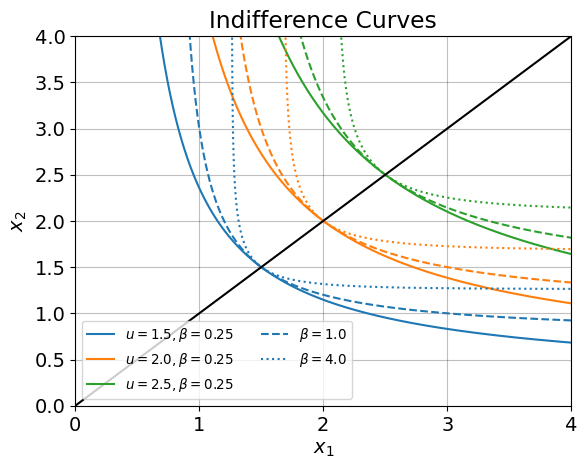

In [ ]:
# these values were used
alpha = 0.5 
betas = [0.25, 1.0, 4.0]
uvals = [1.5, 2.0, 2.5]

# function to compute x2 given x1, u, alpha and beta
def x2_func(x1,u,alpha=0.5,beta=1):
    return ((u**(-beta)-alpha*x1**(-beta))/(1-alpha))**(-1/beta)


# Plotting

# Create figure and axis objects
fig = plt.figure()
# plt.figure is the figure object that contains all plot elements
ax = fig.add_subplot(1,1,1) # 1,1,1 is (nrows, ncols, index)
# add_subplot adds a subplot to the figure. Here we only have one subplot, but we could have more
# e.g. fig.add_subplot(2,2,1) would add a subplot in a 2x2 grid, in the first position

# Main loop to plot indifference curves
# We loop over the values of beta and uvals to plot the indifference curves
x1 = np.linspace(0.01,4.0,10000) # 10000 points from 0.01 to 4
for i,beta in enumerate(betas): # loop over values of beta
    for j,uval in enumerate(uvals): # loop over values of utility
        I = np.log(x1) > np.log(uval) + np.log(alpha)/beta
        # Create a boolean index array I where the condition is met
        # This ensures we only compute x2 where the expression inside the root is positive
        # This avoids complex numbers and NaNs in the plot
        # Try to print I to see what it looks like (Hint: Booleans are expressed with 1's and 0's)
        #print(I)
        
        x2 = x2_func(x1[I],uval,alpha,beta=beta)
        # we compute x2 for given values of x1, uval, alpha and beta
        # we use x1[I] to select only the values of x1 where the condition is met
        # it works because I is a boolean(true/false) array of the same length as x1 so every 
        # 'True' in I selects the corresponding value in x1 which are all the x1 values where the condition is met

        # Labeling - we set them so the graph is the same as Jeppe's
        # we only label the first beta and utility pair and the two other possible betas to avoid cluttering the legend
        if i == 0:
            label = f'$u={uval}, \\beta={beta}$'
        elif j == 0:
            label = f'$\\beta={beta}$'
        else:
            label = None
        
        ax.plot(x1[I],x2,label=label,color=colors[j],linestyle=['-','--',':'][i])
        # we plot the indifference curve with each iteration through uval and beta
        # label is used for the legend
        # color is chosen from the colors list set in the imports section in the top of the file, same utility has same colour
        # linestyle is chosen from a list of linestyles to match Jeppe's style, same beta has same linestyle


# Cosmetics

# 45 degree line
ax.plot([0,4],[0,4],color='black')
# we plot a line from (0,0) to (4,4) with color black
# can use zorder=0 to plot it first and bring it to the background

# Title and labels
ax.set_title('Indifference Curves')
ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')

# Set axis limits and ticks
ax.set_xticks(np.arange(0,4+1,1)) # we add one to include the end point 4, as np.arange stops before the end point
# To replicate Jeppe's style, we set ticks at every integer from 0 to 4
ax.set_xlim(0.0,4.)
ax.set_ylim(0.0,4.)
# we set the x and y axis limits to be from 0 to 4

# Legend
ax.legend(ncols=2,prop={'size': 'x-small'})
# we add a legend with 2 columns and small font size

# Save figure
fig.savefig('output&info\\2d_indifference_curves.png')
# Save the figure as a PNG file with the given filename in the current directory
# You can change the location by providing a path, e.g. 'figures/indifference_curves.png'
# Use either / or \\ in the path, not \ alone


***COMMENT***

Mine and the solution code has slight differences. It is a good exercise to look at the differences, and explain to yourself, why, despite these differences the graphs are almost indistinguishable. You can also consider how, the solution is contained in a function. Functions are good when you need to repeat a task - Here we only need to plot once so function/no function is the same.

**Check:** if `x2_func` is right, it recovers $x_2$ from the utility of a bundle. Remove the `#` once `u_func` from Task 1 and `x2_func` exist:

In [57]:
x1_ = 2.0
x2_ = 1.5
u_ = utility(x1_, x2_, alpha=alpha, beta=1.0)
print(np.isclose(x2_func(x1_, u_, alpha=alpha, beta=1.0), x2_)) # should print True

True


<details>
<summary><strong>Answer</strong></summary>

**45-degree line:** At $x_1=x_2=x$ the utility is $(\alpha x^{-\beta} + (1-\alpha) x^{-\beta})^{-1/\beta} = (x^{-\beta})^{-1/\beta} = x$. So the bundle $(u,u)$ has utility $u$ for every $\beta$, and every curve with that $u$ passes through it.

**Curvature:** A larger $\beta$ bends the curves more. At $\beta=2$ (dotted) the curves are close to a right angle around the 45-degree line: the goods are poor substitutes. At $\beta=0.5$ (dashed) the curves are flatter, so the goods substitute for each other more easily.

</details>

## 5. <a id='toc5_'></a>[Income distribution](#toc0_)

Incomes are right-skewed. The cell below simulates the annual incomes of 2000 households in DKK.

Plot a histogram of the incomes with 40 bins. Show income in thousand DKK (divide by 1000, so the axis stays readable) and label the axes. Add a vertical line at the mean and one at the median with `ax.axvline` (section 5.1 of the plotting notebook), use different colors or line styles, and add a legend. Save the figure.

Print the mean and the median with f-strings, for example `mean income: 334,669 DKK`. The format `:,.0f` writes a number with thousands separators and no decimals. Use `np.mean` and `np.median`.

**Question:** Why is the mean above the median?

In [58]:
# these values are used
rng = np.random.default_rng(2026)
N = 2000
income = 300_000*np.exp(rng.normal(0, 0.5, N)) # DKK per year

In [93]:
mu

np.float64(5.6866834541577775)

In [92]:
np.exp((0+np.log(300000/1000)+0.5)/2)

np.float64(22.239972599129665)

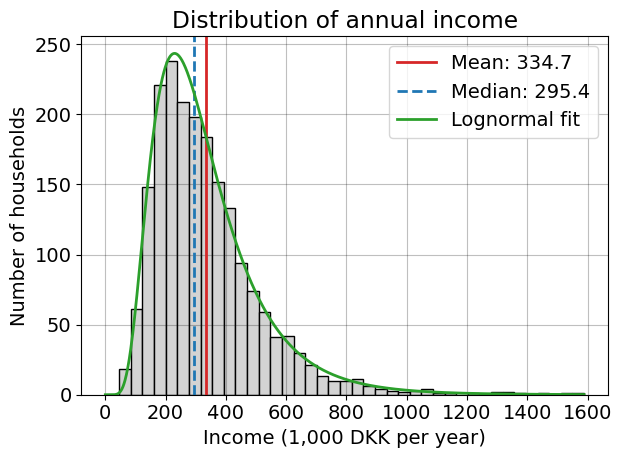

In [ ]:
# plotting the histogram of income
plt.hist(income/1000, bins=40,color='lightgrey', edgecolor='black')

# plot the mean and median lines (using same format as solution code)
mean_income = np.mean(income/1000)
median_income = np.median(income/1000)
plt.axvline(mean_income, color=colors[3], lw=2, label=f'Mean: {mean_income:.1f}') # colors are defined in the imports section, and is a list of colors (try printing colors to see what it looks like)
plt.axvline(median_income, color=colors[0], linestyle='--', lw=2, label=f'Median: {median_income:.1f}') # lw= lineweight(thickness of the line)

# plot a lognormal distribution with the same mean and standard deviation as the income data
# compute the mean and standard deviation using the distribution that income is pulled from above
mu = np.mean(np.log(income/1000))
sigma = 0.5 # variance of the lognormal distribution is the same as the variance of the normal distribution
# import the lognormal distribution from scipy.stats, alternatively you can finde the formula for the lognormal distribution and compute it directly
from scipy.stats import lognorm
# create a range of x values to plot the lognormal distribution
x = np.linspace(1e-8, np.max(income/1000), 1000)
pdf = lognorm.pdf(x, s=sigma, scale=np.exp(mu))
# plot the lognormal distribution, scaled to match the histogram
plt.plot(x, pdf*N*(np.max(income/1000)-1e-8)/40, color=colors[2], lw=2, label='Lognormal fit') # scale the pdf to match the histogram

# cosmetics
plt.title('Distribution of annual income')
plt.xlabel('Income (1,000 DKK per year)')
plt.ylabel('Number of households')
plt.legend()
plt.tight_layout()
plt.show()


<details>
<summary><strong>Answer</strong></summary>

The distribution is skewed to the right: a few households with very high incomes form the long tail. They pull the mean up, while the median, the middle observation, hardly reacts to them. The mean is therefore above the median (here about 334,669 against 295,372 DKK). For a symmetric distribution the two would be close.

</details>

## 6. <a id='toc6_'></a>[The budget set](#toc0_)

A consumer has income $I$ and faces the prices $p_1$ and $p_2$. A bundle $(x_1,x_2)$ is **affordable** if

$$
p_1 x_1 + p_2 x_2 \leq I
$$

The starter cell sets up a grid of bundles. `np.meshgrid` returns two 2-D arrays, `x1_grid` and `x2_grid`, that together list every pair $(x_1,x_2)$ of the grid (see section 5.3 of the plotting notebook). Then:

- **(a)** Select the affordable bundles with a 2-D Boolean mask. *Hint:* indexing a 2-D array with a 2-D mask returns a 1-D array. How many of the 10,000 bundles are affordable?
- **(b)** Make a scatter plot of the affordable bundles, colored by their utility from Task 1, with a colorbar.
- **(c)** Add the budget line $p_1 x_1 + p_2 x_2 = I$.
- **(d)** Add the indifference curves for $u=3.0$ and $u=4.0$, using `x2_func` from Task 4 (or `from A4 import x2_func`) and only the $x_1$ where it is defined.

**Questions:** Which of the two utility levels can the consumer reach? Roughly where is the best affordable bundle?

optimal bundle: x1 = 2.9000, x2 = 4.1707 -> u = 3.4212


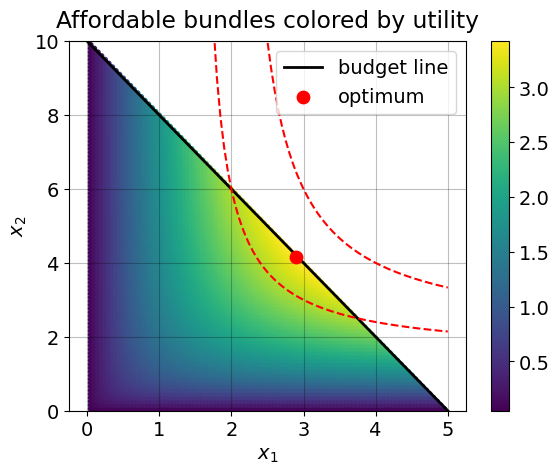

In [ ]:
# these values are used
p1 = 2.0
p2 = 1.0
income = 10.0
alpha = 0.5
beta = 1.0
uvals = [3.0, 4.0]

# (a)-(c)
# grid of bundles (start slightly above 0, because u_func needs x > 0)
N = 100
x1_vec = np.linspace(0.05, income/p1, N)
x2_vec = np.linspace(0.05, income/p2, N) # evenly spaced vecs from a number close to zero to income/price, with 1000 points each
x1_grid, x2_grid = np.meshgrid(x1_vec, x2_vec, indexing='ij') # first index belongs to x1. create a grid of x1 and x2 values for computing utility at all possible combinations of x1 and x2

# create boolean to index with, only points that are feasible given the budget constraint will be True, all others will be False
I = (p1*x1_grid + p2*x2_grid) <= income

# compute utility for each combination of x1 and x2 in the vec, using I to only select feasible combinations
u_grid = utility(x1_grid[I], x2_grid[I], alpha=alpha, beta=beta) # this is still the same utility function defined in the beginning

# find the index of the maximum utility
ui_star = np.argmax(u_grid, keepdims=True)

# using the index find the maximum utility and the corresponding x1 and x2 values
u_star = u_grid[ui_star][0]
x1_star = x1_grid[I].flatten()[ui_star][0] # we both need to index the grids with feasible points and flatten the grid since the optimal index is an integer, that is one dimensional
x2_star = x2_grid[I].flatten()[ui_star][0] # we finally index to 0 to to get a float value instead of an array with one element

assert x1_star*p1 + x2_star*p2 <= income, "The optimal bundle exceeds the budget constraint"

# Plotting - to keep cosmetics the same it is just Jeppe's code but modified with my variable names

fig = plt.figure()
ax = fig.add_subplot(1,1,1)

# i. scatter of affordable bundles colored by utility
h = ax.scatter(x1_grid[I],x2_grid[I],s=10,c=u_grid) # s is the size of the marker, c is colour and passing an array like u_grid creates a colour map corresponding to the values
fig.colorbar(h)

# ii. budget line
ax.plot([0,income/p1],[income/p2,0],color='black',lw=2,label='budget line') # lw = line width
# iii. optimum
ax.scatter(x1_star,x2_star,color='red',s=80,zorder=5,label='optimum') #zorder sets the order of the plot elements, higher numbers are plotted on top of lower numbers

# labels
ax.set_title('Affordable bundles colored by utility',pad=10)
ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_ylim(0,income/p2) # set the y-axis limit to be from 0 to income/p2, the indifference curves will go towards infinity as x1 goes towards zero and the plot will look weird if we don't cut off the axis

ax.legend(loc='upper right')

# (d)
for u in uvals:
    I = np.log(x1_vec) > np.log(u) + np.log(alpha)/beta
    x2 = x2_func(x1_vec[I],u,alpha,beta)
    ax.plot(x1_vec[I],x2,label=f'$u={u}$',color='red',linestyle='--')


# save and print optimal bundle
fig.savefig('output&info\\budgetset.png')

print(f'optimal bundle: x1 = {x1_star:.4f}, x2 = {x2_star:.4f} -> u = {u_star:.4f}')


<details>
<summary><strong>Answer</strong></summary>

The curve for $u=3$ cuts through the affordable set: it meets the budget line at $(2.0,\,6.0)$ and $(3.75,\,2.5)$, and the bundles on the budget line between these points give more than 3. The curve for $u=4$ lies entirely above the budget line, so 4 is out of reach. The best affordable bundle lies on the budget line, where an indifference curve just touches it: roughly $x_1 \approx 2.9$, $x_2 \approx 4.1$ with $u \approx 3.4$. The exact values are $x_1 = 2.929$, $x_2 = 4.142$ and $u = 3.431$. They come from the first-order condition worked out by hand; in Lecture 6 you find them numerically.

</details>

***COMMENT***

argmax only finds solutions on the grid you created, why we get closer to the actual optimum as we increase gridpoints. But computation grows exponentially.

## 7. <a id='toc7_'></a>[Optional: utility in 3D](#toc0_)

**Optional, and beyond the core lecture.** This task uses the reference sections 5.2 (`zorder`) and 5.3 (3D plots) of the plotting notebook. Skip it if time is short.

Draw $u(x_1,x_2)$ as a surface and put indifference curves on it.

1. Compute $u$ on the grid from `np.meshgrid`.
2. Draw the surface with `ax.plot_surface` on a 3D axis and add a colorbar.
3. Draw black indifference curves for $u \in \{1,2,3\}$. A curve consists of the points $(x_1,\,x_2(x_1,u),\,u)$, so use the 3-D `ax.plot(x, y, z)` where `z` equals the constant $u$ at every point. Use `x2_func` from Task 4 (or `from A4 import x2_func`), keep only the $x_1$ where it is defined, and drop points with $x_2$ above the grid.

*Hints:* Without `zorder=99` in the line plot, the surface hides the curves. `ax.invert_xaxis()` brings the origin to the front and is optional.

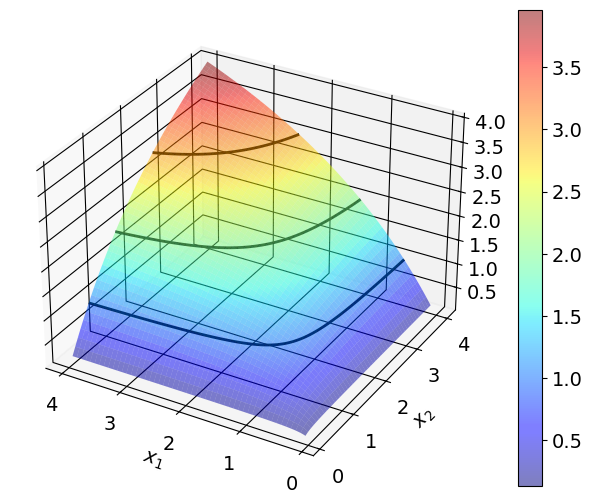

In [ ]:
# imports to plot 3d
from mpl_toolkits.mplot3d import Axes3D # for 3D plots
from matplotlib import cm # for colormaps

# these values are used
alpha = 0.5
beta = 1.0
x1_vec = np.linspace(0.1, 4.0, 1000)
x2_vec = np.linspace(0.1, 4.0, 1000)
uvals = [1.0, 2.0, 3.0]
# both x1_vec and x2_vec are numpy arrays with evenly spaced 1000 points from 0.1 to 4

# 1.
x1_grid,x2_grid = np.meshgrid(x1_vec,x2_vec)
# creates a grid of x1 and x2 values for 3D plotting
# x1_grid and x2_grid are 2D arrays of shape (1000,1000) that is every combination of x1 and x2 values

u_grid = utility(x1_grid,x2_grid,alpha=alpha,beta=beta)
# compute utility for each combination of x1 and x2 in the grid


# 2.-3.
# create function for plotting indifference curves in 3D
def threeD_plot(x1_grid,x2_grid,u_grid):
    # Create figure and axis objects(in 3D) and plot surface
    fig = plt.figure()
    ax = fig.add_subplot(1,1,1,projection='3d')
    h = ax.plot_surface(x1_grid,x2_grid,u_grid,cmap=cm.jet, alpha=0.5) # cmap is the colormap, alpha sets transparency
    # due to contour plot being below the surface, we set alpha to 0.5 to make the surface semi-transparent


    # Indifference curves using contour plot
    for uval in uvals:
        
        # create a mask to only plot where the condition is met
        I = np.log(x1_grid) > np.log(uval) + np.log(alpha)/beta
        u_grid_masked = np.where(I, u_grid, np.nan)
        
        # plot the contour
        ax.contour(x1_grid, x2_grid, u_grid_masked, levels=[uval], colors='black', linewidths=2)
        # we plot the contour where the utility is equal to uval
        # we use the masked grid to avoid plotting where the condition is not met

    # Cosmetics

    fig.colorbar(h) # adds a color bar to indicate the scale of utility values
    ax.invert_xaxis() # invert x axis to match Jeppe's style
    fig.tight_layout(pad=0.1) # adjusts the layout to fit everything in the figure area

    # labels

    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$');
    #; prevents printing the last line output
# plot using the function
threeD_plot(x1_grid,x2_grid,u_grid)

***COMMENT***

Check the lecture solution in A7 and make sure you understand the differences from mine, i.e. using contour vs. manually computing the indifference curves.

**Part B:** Repeat for $\beta = 2$ and compare the two figures.

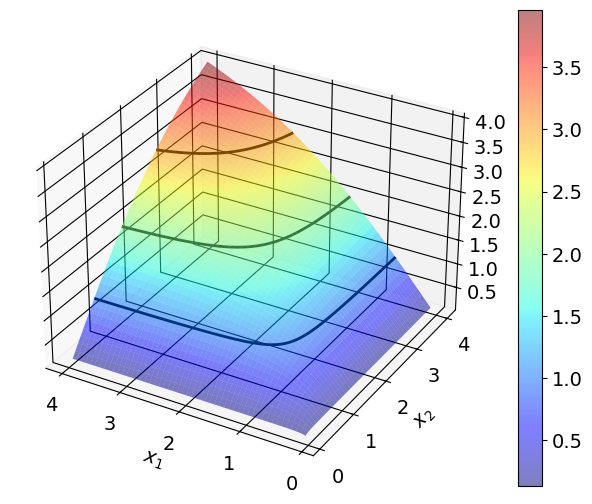

In [107]:
# compute a new utility grid with a different value of beta
beta_alt = 2.0
u_grid_alt = utility(x1_grid,x2_grid,alpha=alpha,beta=beta_alt)

# plot using the function
threeD_plot(x1_grid,x2_grid,u_grid_alt)

<details>
<summary><strong>Comment</strong></summary>

The two surfaces look alike. The difference is in the black curves: for $\beta=2$ they are closer to a right angle, as in Task 4. For example, the $u=3$ curve enters the grid (at $x_2=4$) at $x_1 \approx 2.50$ for $\beta=2$ against $x_1 \approx 2.40$ for $\beta=1$, closer to the corner at $(3,3)$.

</details>

***COMMENT***

Notice how we, with just a few lines of code, could produce another plot, due to the use of functions